# E-Commerce Data Analysis

This project explores an e-commerce dataset to identify sales patterns, customer behavior, product performance, and operational insights.

## 1. Import Libraries

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_cleaning import (
    rename_columns,
    convert_data_types,
    standardize_categories,
    handle_missing_values,
    remove_duplicates
)
from src.analysis import (
    analyze_category_performance,
    analyze_city_performance,
    analyze_region_performance,
    analyze_customer_type,
    analyze_returns,
    analyze_payment_methods,
    analyze_delivery_performance,
    analyze_product_performance,
    analyze_discount_performance,
    calculate_discount_profit_correlation
)
from src.visualization import (
    plot_monthly_revenue,
    plot_category_revenue,
    plot_city_revenue,
    plot_region_revenue,
    plot_return_rate,
    plot_payment_revenue,
    plot_delivery_distribution,
    plot_top_products_quantity,
    plot_top_products_revenue,
    plot_discount_revenue,
    plot_discount_profit_correlation
)

## 2. Load Dataset

In [2]:
df = pd.read_csv("../data/e_ticaret_veri_seti.csv")
df.head()


,siparis_id,musteri_id,siparis_tarihi,sehir,bolge,kategori,urun_adi,adet,birim_fiyat,indirim_orani,kargo_ucreti,odeme_turu,musteri_tipi,teslimat_gunu,musteri_puani,iade_durumu,kar_marji_orani,toplam_tutar
0,SIP101125,MUS1391,2024-01-13 17:06:00,İstanbul,Marmara,Kozmetik,Nemlendirici,1,414.51,0.05,49.9,Kredi Kartı,Yeni,3.0,5.0,Hayır,0.220,443.68
1,SIP100837,MUS1347,2025-03-17 21:13:00,Gaziantep,Güneydoğu Anadolu,Spor,Dambıl Seti,2,1475.15,0.10,29.9,Banka Kartı,VIP,4.0,1.0,Hayır,0.361,2685.17
2,SIP100050,MUS1066,2025-06-03 12:42:00,Kayseri,İç Anadolu,Kitap,İş Analitiği Rehberi,1,289.02,0.05,29.9,Kredi Kartı,Mevcut,6.0,2.0,Hayır,0.348,304.47
3,SIP100263,MUS1008,2024-08-10 15:13:00,Antalya,Akdeniz,Kitap,Girişimcilik,5,194.78,0.00,49.9,Kapıda Ödeme,Yeni,3.0,5.0,Hayır,0.250,1023.80
4,SIP100707,MUS1291,2024-08-19 08:24:00,Gaziantep,Güneydoğu Anadolu,Elektronik,Powerbank,3,841.80,0.05,39.9,Dijital Cüzdan,Mevcut,4.0,5.0,Hayır,0.280,2439.03


## 3. Initial Data Inspection

In [3]:
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Dataset shape: (1428, 18)
Number of rows: 1428
Number of columns: 18


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1428 entries, 0 to 1427
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   siparis_id       1428 non-null   str    
 1   musteri_id       1428 non-null   str    
 2   siparis_tarihi   1428 non-null   str    
 3   sehir            1403 non-null   str    
 4   bolge            1428 non-null   str    
 5   kategori         1428 non-null   str    
 6   urun_adi         1428 non-null   str    
 7   adet             1428 non-null   int64  
 8   birim_fiyat      1428 non-null   float64
 9   indirim_orani    1412 non-null   float64
 10  kargo_ucreti     1428 non-null   float64
 11  odeme_turu       1393 non-null   str    
 12  musteri_tipi     1386 non-null   str    
 13  teslimat_gunu    1400 non-null   float64
 14  musteri_puani    1372 non-null   float64
 15  iade_durumu      1428 non-null   str    
 16  kar_marji_orani  1428 non-null   float64
 17  toplam_tutar     1428 non

In [5]:
df.describe()

,adet,birim_fiyat,indirim_orani,kargo_ucreti,teslimat_gunu,musteri_puani,kar_marji_orani,toplam_tutar
count,1428.000000,1428.000000,1412.000000,1428.000000,1400.000000,1372.000000,1428.000000,1428.000000
mean,2.136555,658.477654,0.052054,39.725140,3.370714,4.002187,0.302799,1370.590336
std,2.015770,1042.414639,0.060115,14.185017,1.825990,1.096707,0.069795,2961.689500
min,1.000000,93.110000,0.000000,0.000000,1.000000,0.000000,0.180000,89.680000
25%,1.000000,199.185000,0.000000,29.900000,2.000000,3.000000,0.244750,323.855000
50%,2.000000,287.120000,0.050000,39.900000,3.000000,4.000000,0.305000,669.135000
75%,3.000000,819.177500,0.100000,49.900000,4.000000,5.000000,0.362000,1390.950000
max,38.000000,18145.230000,0.200000,59.900000,31.000000,7.000000,0.420000,63870.200000


## 4. Rename Columns

In [6]:
df = rename_columns(df)
df.head()

,order_id,customer_id,order_date,city,region,category,product_name,quantity,unit_price,discount_rate,shipping_fee,payment_method,customer_type,delivery_days,customer_rating,return_status,profit_margin_rate,total_amount
0,SIP101125,MUS1391,2024-01-13 17:06:00,İstanbul,Marmara,Kozmetik,Nemlendirici,1,414.51,0.05,49.9,Kredi Kartı,Yeni,3.0,5.0,Hayır,0.220,443.68
1,SIP100837,MUS1347,2025-03-17 21:13:00,Gaziantep,Güneydoğu Anadolu,Spor,Dambıl Seti,2,1475.15,0.10,29.9,Banka Kartı,VIP,4.0,1.0,Hayır,0.361,2685.17
2,SIP100050,MUS1066,2025-06-03 12:42:00,Kayseri,İç Anadolu,Kitap,İş Analitiği Rehberi,1,289.02,0.05,29.9,Kredi Kartı,Mevcut,6.0,2.0,Hayır,0.348,304.47
3,SIP100263,MUS1008,2024-08-10 15:13:00,Antalya,Akdeniz,Kitap,Girişimcilik,5,194.78,0.00,49.9,Kapıda Ödeme,Yeni,3.0,5.0,Hayır,0.250,1023.80
4,SIP100707,MUS1291,2024-08-19 08:24:00,Gaziantep,Güneydoğu Anadolu,Elektronik,Powerbank,3,841.80,0.05,39.9,Dijital Cüzdan,Mevcut,4.0,5.0,Hayır,0.280,2439.03


In [7]:
df.columns.tolist()

['order_id',
 'customer_id',
 'order_date',
 'city',
 'region',
 'category',
 'product_name',
 'quantity',
 'unit_price',
 'discount_rate',
 'shipping_fee',
 'payment_method',
 'customer_type',
 'delivery_days',
 'customer_rating',
 'return_status',
 'profit_margin_rate',
 'total_amount']

## 5. Data Type Conversion

In [8]:
df = convert_data_types(df)

df["order_date"].dtype

dtype('<M8[us]')

## 6. Data Cleaning

The dataset is cleaned by handling missing values, standardizing categorical values, and removing duplicate records.

### 6.1 Missing Values

In [9]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0].sort_values(ascending=False)

customer_rating    56
customer_type      42
payment_method     35
delivery_days      28
city               25
discount_rate      16
dtype: int64

### 6.2 Categorical Data Standardization

In [10]:
df = standardize_categories(df)

In [11]:
for column in ["city", "category", "customer_type", "payment_method"]:
    df[column] = df[column].str.strip()

### 6.3 Handling Missing Values

In [12]:
df = handle_missing_values(df)

In [13]:
df.isnull().sum()

order_id               0
customer_id            0
order_date             0
city                   0
region                 0
category               0
product_name           0
quantity               0
unit_price             0
discount_rate          0
shipping_fee           0
payment_method         0
customer_type          0
delivery_days          0
customer_rating       56
return_status          0
profit_margin_rate     0
total_amount           0
dtype: int64

### 6.4 Duplicate Records

In [14]:
duplicate_count = df.duplicated().sum()

print(f"Duplicate records found: {duplicate_count}")

Duplicate records found: 28


In [15]:
df = remove_duplicates(df)

print(f"Dataset shape after removing duplicates: {df.shape}")

Dataset shape after removing duplicates: (1400, 18)


### 6.5 Final Data Validation

In [16]:
print(f"Rows: {len(df)}")
print(f"Columns: {len(df.columns)}")
print(f"Duplicates: {df.duplicated().sum()}")
print(f"Missing values: {df.isnull().sum().sum()}")

Rows: 1400
Columns: 18
Duplicates: 0
Missing values: 56


# 7. Exploratory Data Analysis

## 7.1 Numerical Summary

In [17]:
numeric_columns = [
    "quantity",
    "unit_price",
    "total_amount",
    "discount_rate",
    "shipping_fee",
    "delivery_days",
    "customer_rating",
    "profit_margin_rate"
]

df[numeric_columns].describe()

,quantity,unit_price,total_amount,discount_rate,shipping_fee,delivery_days,customer_rating,profit_margin_rate
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1344.000000,1400.000000
mean,2.142857,660.121793,1376.644357,0.051750,39.693000,3.356429,4.001488,0.302516
std,2.030403,1050.381544,2986.105341,0.059652,14.220892,1.770447,1.096938,0.069879
min,1.000000,93.110000,89.680000,0.000000,0.000000,1.000000,0.000000,0.180000
25%,1.000000,198.700000,327.310000,0.000000,29.900000,2.000000,3.000000,0.243750
50%,2.000000,287.120000,669.135000,0.050000,39.900000,3.000000,4.000000,0.305000
75%,3.000000,817.025000,1390.950000,0.100000,49.900000,4.000000,5.000000,0.362000
max,38.000000,18145.230000,63870.200000,0.200000,59.900000,31.000000,7.000000,0.420000


## 7.2 Categorical Data Overview

In [18]:
categorical_columns = [
    "city",
    "region",
    "category",
    "payment_method",
    "customer_type",
    "return_status"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- city ---
city
İstanbul     303
Ankara       169
İzmir        154
Antalya      108
Konya         87
Bursa         86
Adana         77
Gaziantep     66
Mersin        57
Eskişehir     57
Samsun        57
Trabzon       55
Kayseri       54
Kocaeli       45
Unknown       25
Name: count, dtype: int64

--- region ---
region
Marmara              443
İç Anadolu           370
Akdeniz              244
Ege                  161
Karadeniz            115
Güneydoğu Anadolu     67
Name: count, dtype: int64

--- category ---
category
Kitap          253
Elektronik     241
Spor           235
Ofis           230
Kozmetik       225
Ev ve Yaşam    216
Name: count, dtype: int64

--- payment_method ---
payment_method
Kredi Kartı       681
Banka Kartı       223
Dijital Cüzdan    199
Havale/EFT        148
Kapıda Ödeme      100
Unknown            35
Kart               14
Name: count, dtype: int64

--- customer_type ---
customer_type
Mevcut     674
Yeni       520
VIP        164
Unknown     42
Name: count, dtype

## 7.3 Outlier Analysis

The IQR method is used to identify statistically unusual observations. Outliers are inspected rather than automatically removed because they may represent legitimate high-value or bulk orders.

In [19]:
def detect_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    return outliers, lower_bound, upper_bound

In [20]:
outlier_columns = [
    "quantity",
    "unit_price",
    "total_amount",
    "delivery_days"
]

for column in outlier_columns:
    outliers, lower, upper = detect_outliers(df, column)
    
    print(f"\n--- {column} ---")
    print(f"Lower bound: {lower:.2f}")
    print(f"Upper bound: {upper:.2f}")
    print(f"Outlier count: {len(outliers)}")


--- quantity ---
Lower bound: -2.00
Upper bound: 6.00
Outlier count: 6

--- unit_price ---
Lower bound: -728.79
Upper bound: 1744.51
Outlier count: 92

--- total_amount ---
Lower bound: -1268.15
Upper bound: 2986.41
Outlier count: 136

--- delivery_days ---
Lower bound: -1.00
Upper bound: 7.00
Outlier count: 5


Outliers were retained because statistical extremeness does not necessarily indicate data quality issues. For example, large quantities or high-value orders may represent legitimate bulk purchases.

# 8. Feature Engineering

In [21]:
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["year_month"] = df["order_date"].dt.to_period("M")

In [22]:
df[[
    "order_date",
    "order_year",
    "order_month",
    "year_month"
]].head()

,order_date,order_year,order_month,year_month
0,2024-01-13 17:06:00,2024,1,2024-01
1,2025-03-17 21:13:00,2025,3,2025-03
2,2025-06-03 12:42:00,2025,6,2025-06
3,2024-08-10 15:13:00,2024,8,2024-08
4,2024-08-19 08:24:00,2024,8,2024-08


# 9. Business Analysis

## 9.1 Monthly Revenue

In [23]:
monthly_revenue = (
    df.groupby("year_month")["total_amount"]
    .sum()
    .reset_index()
)

monthly_revenue

,year_month,total_amount
0,2024-01,75464.23
1,2024-02,63391.33
2,2024-03,78305.64
3,2024-04,70563.89
4,2024-05,91193.79
5,2024-06,49269.54
6,2024-07,64465.23
7,2024-08,77081.84
8,2024-09,59045.79
9,2024-10,81231.70


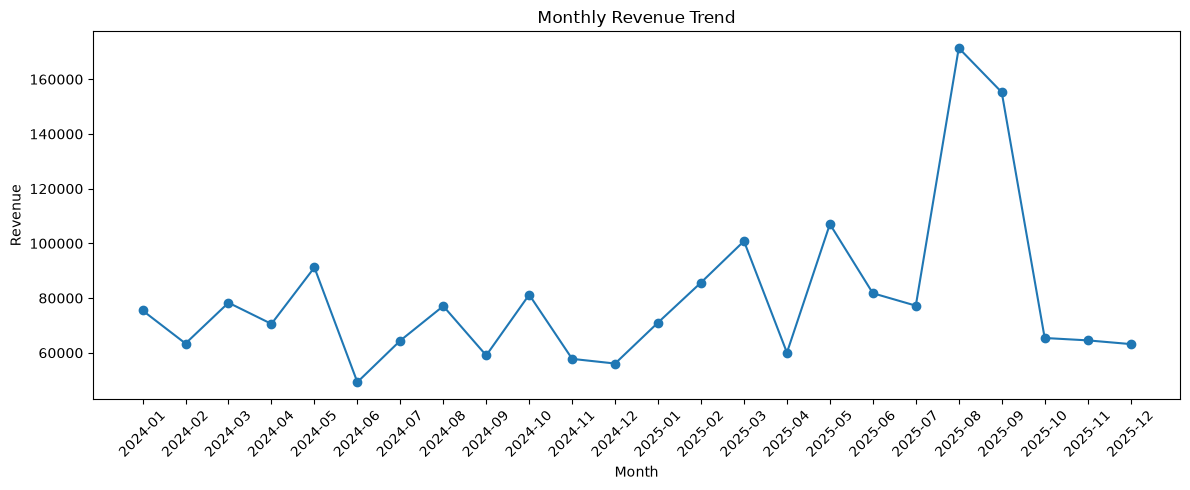

In [24]:
plot_monthly_revenue(monthly_revenue)

## 9.2 Category Performance

In [25]:
category_analysis = analyze_category_performance(df)

category_analysis

,order_count,total_revenue,average_order_value
category,,,
Elektronik,241,765989.55,3178.379876
Spor,235,331770.62,1411.789872
Ofis,230,291376.57,1266.854652
Kozmetik,225,204676.10,909.671556
Ev ve Yaşam,216,187901.01,869.912083
Kitap,253,145588.25,575.447628


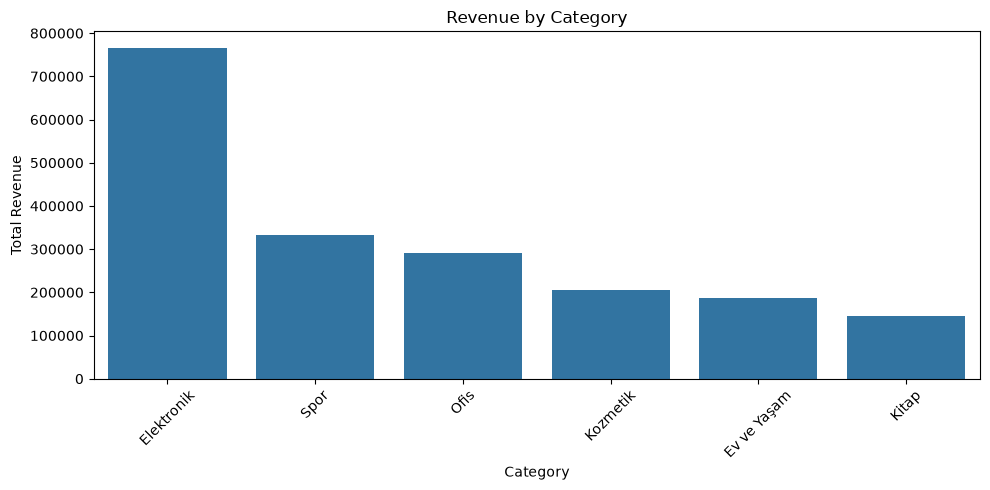

In [26]:
plot_category_revenue(category_analysis)

## 9.3 City Performance

In [27]:
city_analysis = analyze_city_performance(df)

city_analysis

,order_count,total_revenue,average_order_value
city,,,
İstanbul,303,425461.93,1404.164785
Ankara,169,272952.97,1615.106331
İzmir,154,184523.39,1198.203831
Antalya,108,129851.32,1202.327037
Mersin,57,113273.31,1987.251053
Kayseri,54,111551.65,2065.771296
Gaziantep,66,107211.78,1624.420909
Konya,87,101798.84,1170.101609
Bursa,86,98335.67,1143.438023


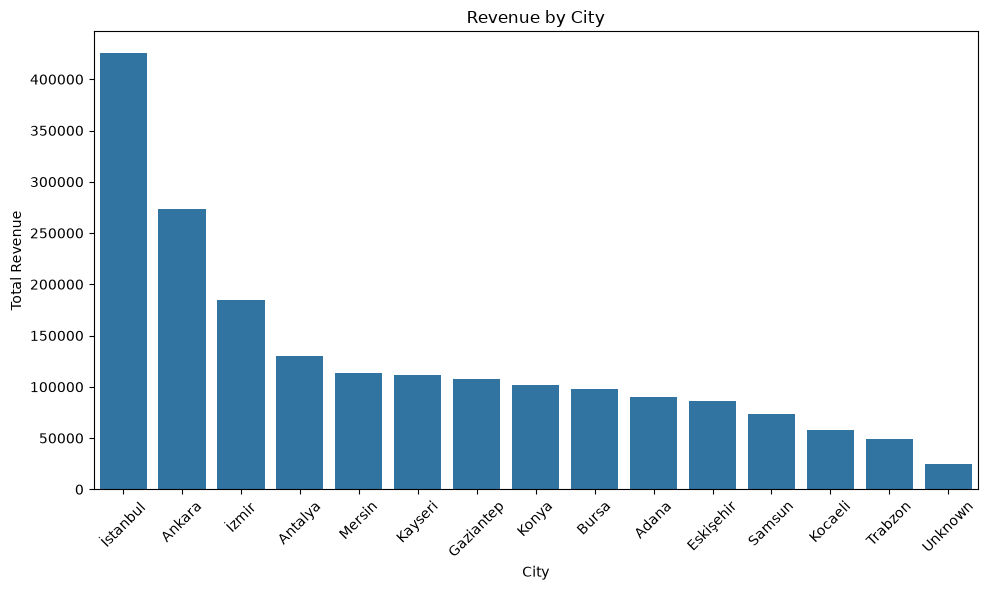

In [28]:
plot_city_revenue(city_analysis)

## 9.4 Region Performance

In [29]:
region_analysis = analyze_region_performance(df)

region_analysis

,order_count,total_revenue,average_order_value
region,,,
Marmara,443,591977.29,1336.291851
İç Anadolu,370,575993.79,1556.739973
Akdeniz,244,335787.43,1376.177992
Ege,161,191275.00,1188.043478
Karadeniz,115,124636.69,1083.797304
Güneydoğu Anadolu,67,107631.90,1606.446269


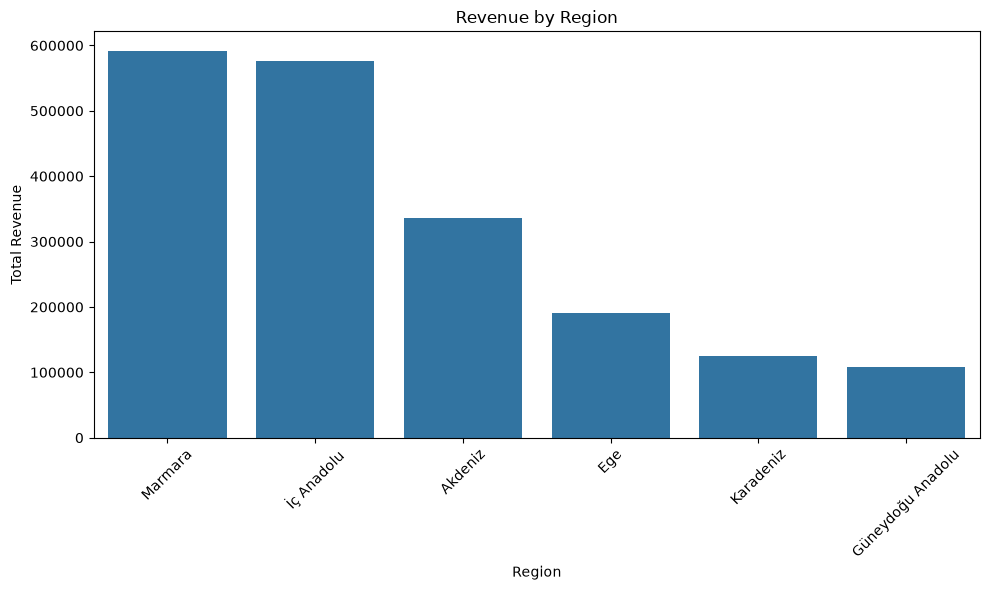

In [30]:
plot_region_revenue(region_analysis)

## 9.5 Customer Type

In [31]:
customer_type_analysis = analyze_customer_type(df)

customer_type_analysis

,order_count,total_revenue,average_order_value
customer_type,,,
Mevcut,674,908746.16,1348.288071
Yeni,520,745445.01,1433.548096
VIP,164,210826.97,1285.530305
Unknown,42,62283.96,1482.951429


## 9.6 Return Analysis

In [32]:
category_returns = analyze_returns(df)

category_returns

,order_count,return_count,return_rate
category,,,
Spor,235,25,10.638298
Ev ve Yaşam,216,20,9.259259
Kitap,253,23,9.090909
Elektronik,241,21,8.713693
Kozmetik,225,18,8.000000
Ofis,230,10,4.347826


In [33]:
return_rate = (
    df["return_status"]
    .eq("Evet")
    .mean() * 100
)

print(f"Overall return rate: {return_rate:.2f}%")

Overall return rate: 8.36%


In [34]:
category_returns = (
    df.groupby("category")
    .agg(
        order_count=("order_id", "count"),
        return_count=("return_status", lambda x: (x == "Evet").sum())
    )
)

category_returns["return_rate"] = (
    category_returns["return_count"]
    / category_returns["order_count"]
    * 100
)

category_returns = category_returns.sort_values(
    "return_rate",
    ascending=False
)

category_returns

,order_count,return_count,return_rate
category,,,
Spor,235,25,10.638298
Ev ve Yaşam,216,20,9.259259
Kitap,253,23,9.090909
Elektronik,241,21,8.713693
Kozmetik,225,18,8.000000
Ofis,230,10,4.347826


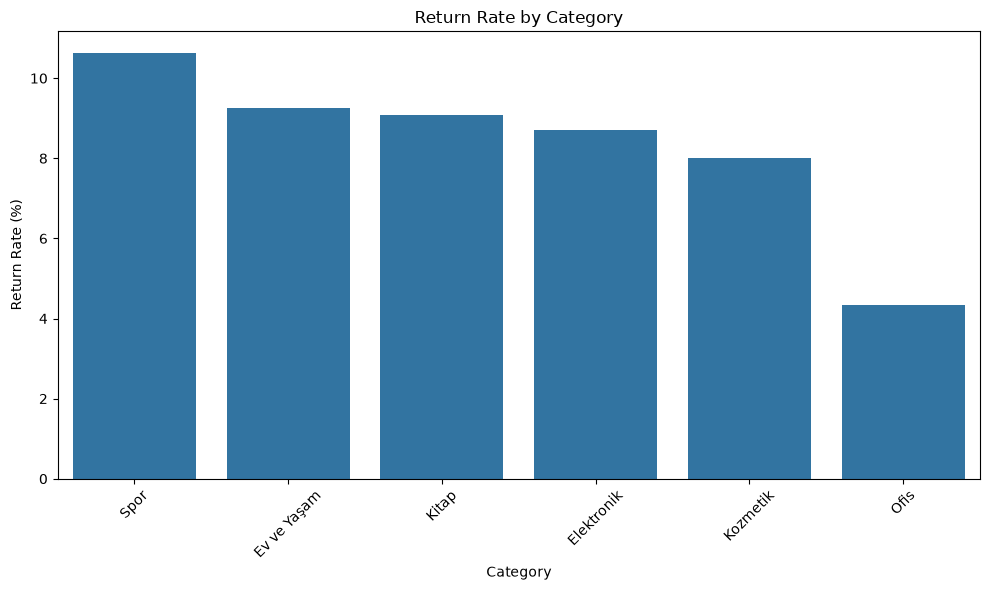

In [35]:
plot_return_rate(category_returns)

The overall return rate is 8.36%. Return rates vary across categories, with Sports showing the highest observed return rate and Office showing the lowest. These differences describe patterns in the dataset but do not establish causal relationships.

## 9.7 Payment Method

In [36]:
payment_analysis = analyze_payment_methods(df)

payment_analysis

,order_count,total_revenue,average_order_value
payment_method,,,
Kredi Kartı,681,888918.77,1305.313906
Dijital Cüzdan,199,330828.72,1662.455879
Banka Kartı,223,301332.04,1351.264753
Havale/EFT,148,222124.53,1500.841419
Kapıda Ödeme,100,104370.13,1043.701300
Unknown,35,54560.24,1558.864000
Kart,14,25167.67,1797.690714


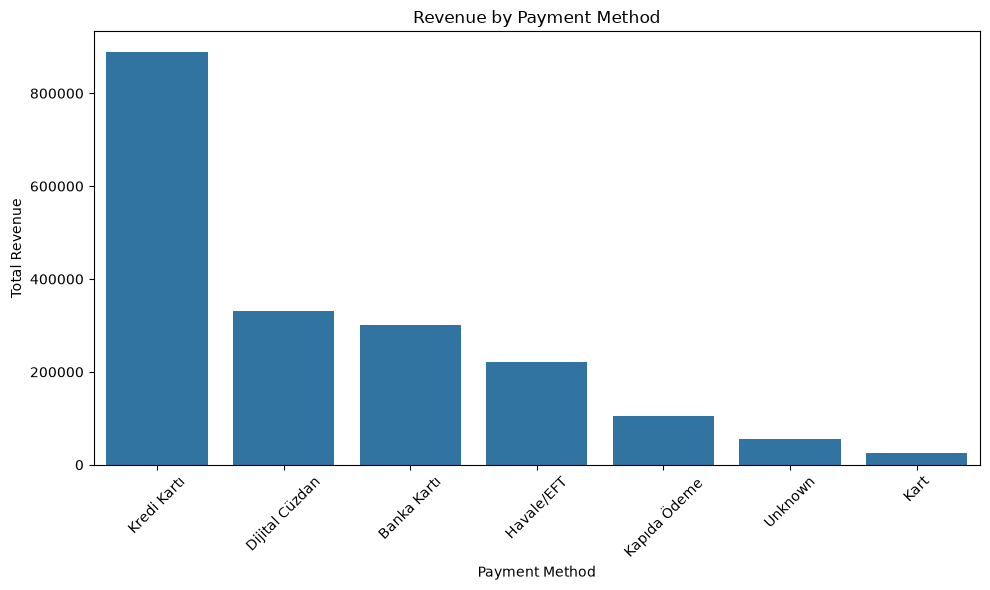

In [37]:
plot_payment_revenue(payment_analysis)

## 9.8 Delivery Performance

In [38]:
delivery_distribution = (
    df["delivery_days"]
    .value_counts()
    .sort_index()
)

delivery_distribution

delivery_days
1.0     161
2.0     273
3.0     366
4.0     291
5.0     200
6.0      87
7.0      17
8.0       2
18.0      1
24.0      1
31.0      1
Name: count, dtype: int64

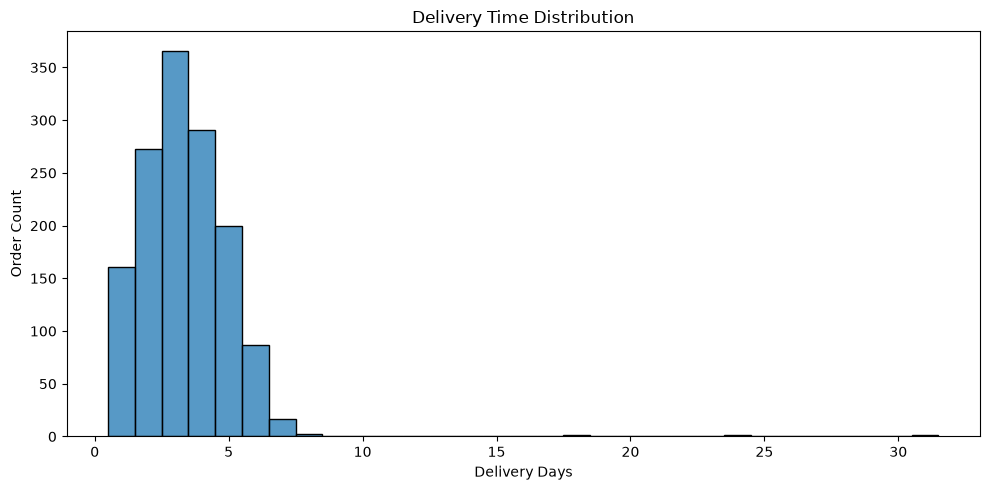

In [39]:
plot_delivery_distribution(df)

In [40]:
average_delivery_time, delivery_rating_correlation = (
    analyze_delivery_performance(df)
)

print(f"Average delivery time: {average_delivery_time:.2f} days")
print(
    f"Correlation between delivery time and customer rating: "
    f"{delivery_rating_correlation:.3f}"
)

Average delivery time: 3.36 days
Correlation between delivery time and customer rating: 0.004


The observed linear correlation between delivery time and customer rating is close to zero in this dataset. This indicates that no meaningful linear relationship is observed between these two variables in the available data.

## 9.9 Product Performance

### Top Products by Quantity Sold

In [41]:
top_products_quantity, top_products_revenue = (
    analyze_product_performance(df)
)

top_products_quantity

product_name
Zaman Yönetimi          138
Webcam                  133
Spor Çantası            120
Python Notları          119
Girişimcilik            114
Not Tutucu              113
Mouse Pad               113
İş Analitiği Rehberi    108
Veri Bilimi 101         107
Kahve Kupası            105
Name: quantity, dtype: int64

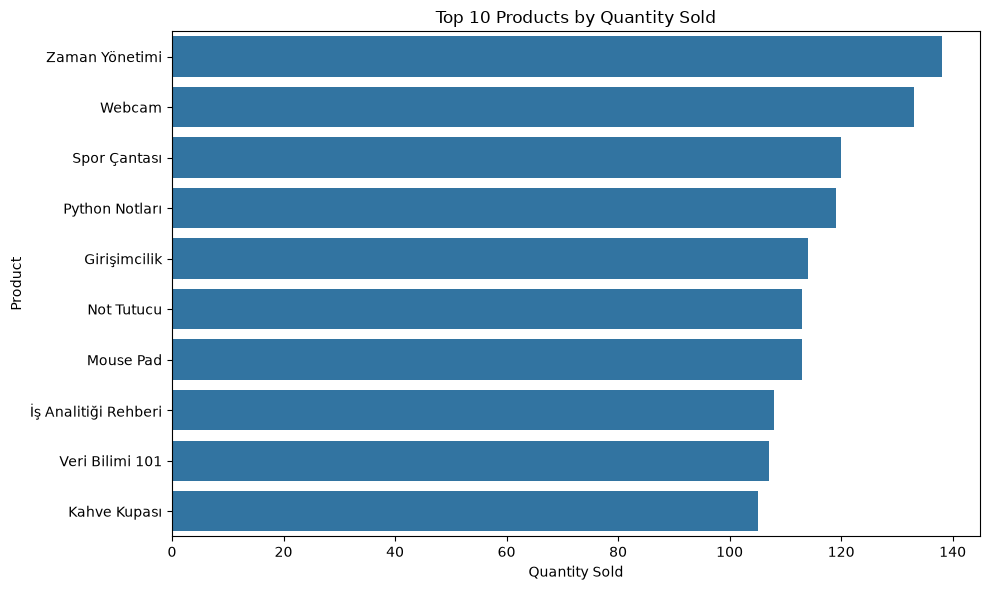

In [42]:
plot_top_products_quantity(top_products_quantity)

### Top Products by Revenue

In [43]:
top_products_revenue

product_name
Akıllı Saat           337672.50
Mekanik Klavye        231324.46
Kablosuz Kulaklık     121104.74
Webcam                117803.46
Dambıl Seti           113939.47
Bluetooth Hoparlör    112022.61
Spor Çantası          100390.71
Powerbank              77386.24
Nemlendirici           73402.38
Masa Lambası           69615.68
Name: total_amount, dtype: float64

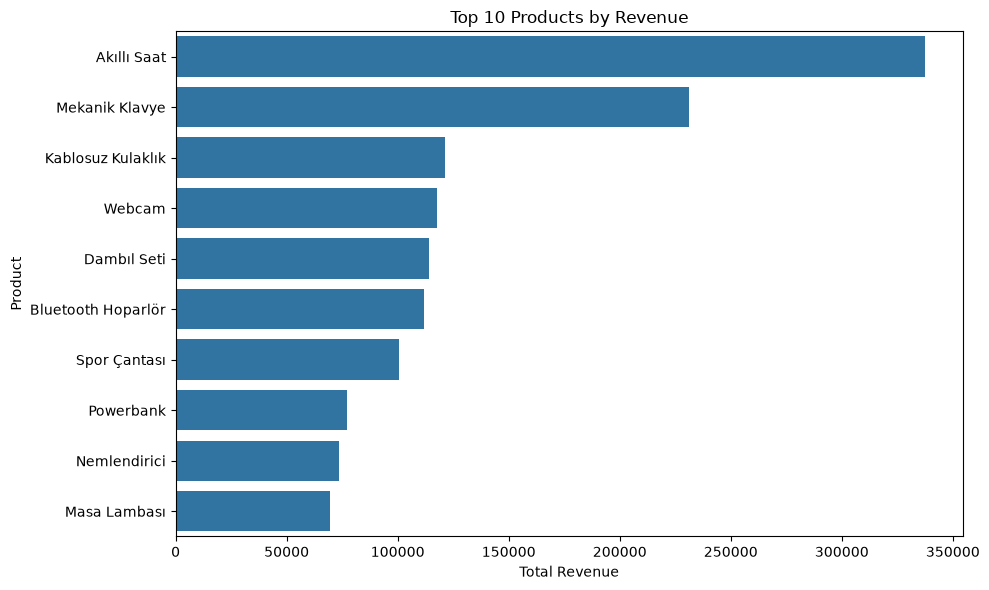

In [44]:
plot_top_products_revenue(top_products_revenue)

## 9.10 Discount & Profitability

### Revenue and Order Value by Discount Rate

In [45]:
discount_analysis = analyze_discount_performance(df)

discount_analysis

,order_count,total_revenue,average_order_value
discount_rate,,,
0.00,660,982973.56,1489.353879
0.05,292,346689.52,1187.292877
0.10,238,312109.87,1311.386008
0.15,159,228308.29,1435.901195
0.20,51,57220.86,1121.977647


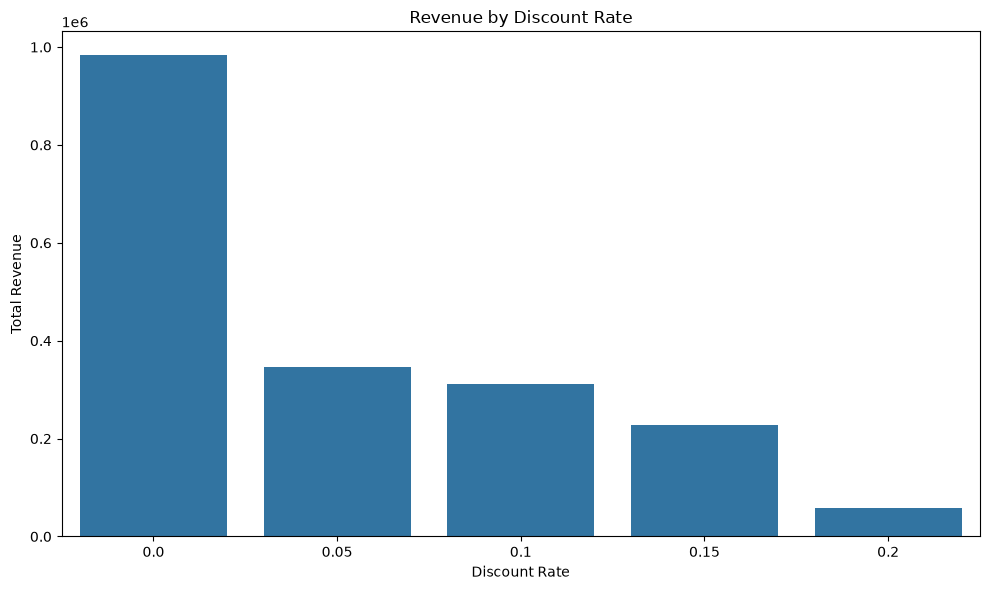

In [46]:
plot_discount_revenue(discount_analysis)

### Discount Rate vs Profit Margin

In [47]:
discount_profit_correlation = (
    calculate_discount_profit_correlation(df)
)

print(
    f"Correlation between discount rate and profit margin rate: "
    f"{discount_profit_correlation:.3f}"
)

Correlation between discount rate and profit margin rate: -0.002


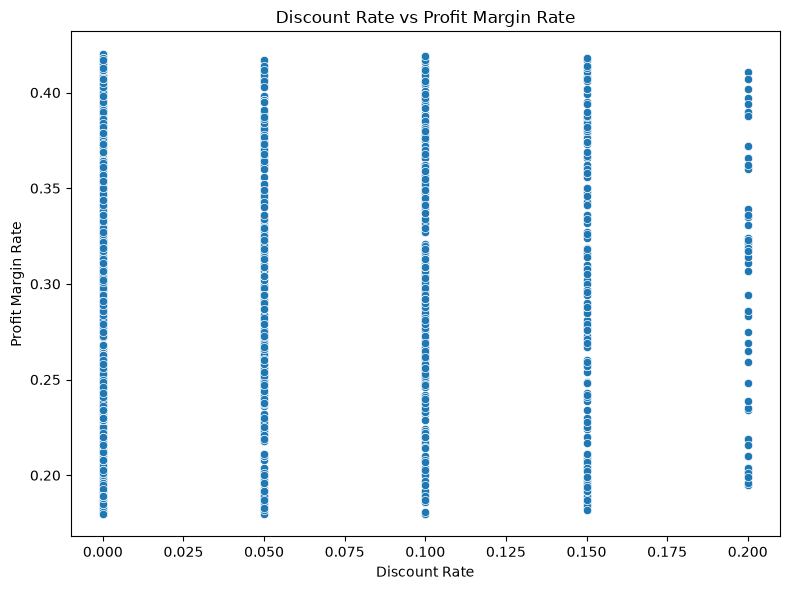

In [48]:
plot_discount_profit_correlation(df)

The observed correlation between discount rate and profit margin rate is close to zero in this dataset. Therefore, no meaningful linear relationship is observed between these variables based on the available data.

# 10. Key Findings

The analysis identified several notable patterns in the e-commerce dataset:

- Electronics generated the highest total revenue among all categories.
- Books had the highest order count but the lowest average order value among the categories.
- Istanbul generated the highest total revenue among cities.
- Some cities such as Kayseri and Mersin showed relatively high average order values despite lower order volumes.
- The overall return rate was approximately 8.36%.
- Return rates varied across product categories, with Sports showing the highest observed rate.
- The average delivery time was approximately 3.37 days.
- The observed linear correlation between delivery time and customer rating was close to zero.
- Products with the highest sales volume were not necessarily the products generating the highest revenue.
- The observed linear correlation between discount rate and profit margin rate was close to zero.